# Multiple Variable Linear Regression

#### **Extend the linear regression model routines to support multiple features.**

- A linear regression model with multiple input features is known as Multiple Linear Regression.
- It is an extension of simple linear regression that allows for the prediction of a dependent variable based on multiple independent variables.

<br>

## **Multiple Linear Regression Summary**

For a model with multiple Features, the linear model can be expressed as:
$$f_{\mathbf{w},b}(\mathbf{x}) =  w_1x_1 + w_2x_2 +... + w_{n}x_{n} + b \tag{1}$$
or in vector notation:
$$f_{\mathbf{w}, b}(\mathbf{x}) = \mathbf{w} \cdot \mathbf{x} + b \tag{2}$$
where,

- $\mathbf{w} = [w_1, w_2, w_3, ..., w_{n}]$ (parameters of the model)

- b is a scalar parameter

- n is the number of features

- $\mathbf{x} = [x_1, x_2, x_3, ..., x_{n}]$ (input feature vector)

- $\mathbf{w} \cdot \mathbf{x} = [w_1x_1 + w_2x_2 + ... + w_{n}x_{n}]$ is the linear combination of the input features and their corresponding weights.

In [1]:
import copy, math
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=2)

#### **Example: Housing Price Prediction**

Let's consider an example of housing price prediction. The training dataset contains three examples with four features (size, bedrooms, floors and, age) shown in the table below.

| Size (sqft) | Number of Bedrooms  | Number of floors | Age of  Home | Price (1000s dollars)  |   
| ----------------| ------------------- |----------------- |--------------|-------------- |  
| 2104            | 5                   | 1                | 45           | 460           |  
| 1416            | 3                   | 2                | 40           | 232           |  
| 852             | 2                   | 1                | 35           | 178           |  

We'll build a linear regression model using these values so you can then predict the price for other houses.

In [2]:
X_train = np.array([[2104, 5, 1, 45], [1416, 3, 2, 40], [852, 2, 1, 35]])
y_train = np.array([460, 232, 178])

Similar to the table above, examples are stored in a NumPy matrix `X_train`. Each row of the matrix represents one example. When you have $m$ training examples ( $m$ is three in our example), and there are $n$ features (four in our example), $\mathbf{X}$ is a matrix with dimensions ($m$, $n$) (m rows, n columns).


$$\mathbf{X} = 
\begin{pmatrix}
 x^{(0)}_0 & x^{(0)}_1 & \cdots & x^{(0)}_{n-1} \\ 
 x^{(1)}_0 & x^{(1)}_1 & \cdots & x^{(1)}_{n-1} \\
 \cdots \\
 x^{(m-1)}_0 & x^{(m-1)}_1 & \cdots & x^{(m-1)}_{n-1} 
\end{pmatrix}
$$
notation:
- $\mathbf{x}^{(i)}$ is vector containing example i. $\mathbf{x}^{(i)}$ $ = (x^{(i)}_0, x^{(i)}_1, \cdots,x^{(i)}_{n-1})$
- $x^{(i)}_j$ is element j in example i. The superscript in parenthesis indicates the example number while the subscript represents an element.

In [3]:
print(f"X Shape: {X_train.shape}, X Type: {type(X_train)}")
print(X_train)
print(f"y Shape: {y_train.shape}, y Type: {type(y_train)}")
print(y_train)

X Shape: (3, 4), X Type: <class 'numpy.ndarray'>
[[2104    5    1   45]
 [1416    3    2   40]
 [ 852    2    1   35]]
y Shape: (3,), y Type: <class 'numpy.ndarray'>
[460 232 178]


For demonstration, $\mathbf{w}$ and $b$ will be loaded with some initial selected values that are near the optimal. $\mathbf{w}$ is a 1-D NumPy vector.

In [4]:
b_init = 785.1811367994083
w_init = np.array([0.39133535, 18.75376741, -53.36032453, -26.42131618])
print(f"w_init Shape: {w_init.shape}, b_init Type: {type(b_init)}")

w_init Shape: (4,), b_init Type: <class 'float'>


### **Vectorization**

Note that equation (1) can be implemented using the dot product as in (2). We can make use of vector operations to speed up predictions.

NumPy `np.dot()` can be used to perform a vector dot product.

`f = np.dot(X, w) + b` will compute the predictions for all examples in one line of code.

In [5]:
def vectorize(x, w, b):

    p = np.dot(x, w) + b
    return p

In [6]:
# get a row from our training data
x_vec = X_train[0,:]
print(f"x_vec Shape: {x_vec.shape}, x_vec Value: {x_vec}")

# make a prediction
f_wb = vectorize(x_vec, w_init, b_init)
print(f"f_wb Shape; {f_wb.shape}, Prediction: {f_wb}")

x_vec Shape: (4,), x_vec Value: [2104    5    1   45]
f_wb Shape; (), Prediction: 459.99999761940825


### **Compute Cost With Multiple Variables**

The equation of the cost function with multiple variables $J(\mathbf{w},b)$ is:

$$J(\mathbf{w},b) = \frac{1}{2m} \sum\limits_{i = 1}^{m} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)})^2 \tag{3}$$

where:

$$f_{\mathbf{w},b}(\mathbf{x}^{(i)}) = \mathbf{w} \cdot \mathbf{x}^{(i)} + b  \tag{4}$$

Below is the implementation of the cost function with multiple variables. The function takes in the input feature matrix `X`, the output vector `y`, the weight vector `w`, and the bias term `b`. It computes the cost using the formula above and returns the cost value.

In [7]:
def compute_cost(X, y, w, b):

    m = X.shape[0]
    cost = 0.0

    for i in range(m):
        f_wb_i = np.dot(X[i], w) + b
        cost = cost + (f_wb_i - y[i])**2

    cost = cost / (2 * m)
    return cost

In [8]:
# Compute and Display cost using our pre-chosen optimal parameters.
cost = compute_cost(X_train, y_train, w_init, b_init)
print(f'Cost at optimal w: {cost}')

Cost at optimal w: 1.5578904880036537e-12


### **Gradient Descent With Multiple Variables**

Gradient Descent algorithm for multiple variables is similar to the one for a single variable. The gradient is defined as:

$$\begin{align*} \text{repeat}&\text{ until convergence:} \; \lbrace \newline\;
& w_j = w_j -  \alpha \frac{\partial J(\mathbf{w},b)}{\partial w_j} \tag{5}  \; & \text{for j = 1..n}\newline
&b\ \ = b -  \alpha \frac{\partial J(\mathbf{w},b)}{\partial b}  \newline \rbrace
\end{align*}$$

where, n is the number of features, parameters $w_j$,  $b$, are updated simultaneously and where  

$$
\begin{align}
\frac{\partial J(\mathbf{w},b)}{\partial w_j}  &= \frac{1}{m} \sum\limits_{i = 1}^{m} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)})x_{j}^{(i)} \tag{6}  \\
\frac{\partial J(\mathbf{w},b)}{\partial b}  &= \frac{1}{m} \sum\limits_{i = 1}^{m} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}) \tag{7}
\end{align}
$$
* m is the number of training examples in the data set

    
*  $f_{\mathbf{w},b}(\mathbf{x}^{(i)})$ is the model's prediction, while $y^{(i)}$ is the target value

### **Compute Gradient with Multiple Variables**

An implementation for calculating the equations (6) and (7) is below. There are many ways to implement this. In this version, there is an
- outer loop over all m examples. 
    - $\frac{\partial J(\mathbf{w},b)}{\partial b}$ for the example can be computed directly and accumulated
    - in a second loop over all n features:
        - $\frac{\partial J(\mathbf{w},b)}{\partial w_j}$ is computed for each $w_j$.

In [9]:
def compute_gradient(X, y, w, b):

    m, n = X.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.

    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err * X[i, j]
        dj_db = dj_db + err

    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

In [10]:
# Compute and Display gradient
tmp_dj_dw, tmp_dj_db = compute_gradient(X_train, y_train, w_init, b_init)
print(f'dj_dw at initial w,b: {tmp_dj_dw}')
print(f'dj_db at initial w,b: \n {tmp_dj_db}')

dj_dw at initial w,b: [-2.73e-03 -6.27e-06 -2.22e-06 -6.92e-05]
dj_db at initial w,b: 
 -1.673925169143331e-06


### **Gradient Descent with Multiple Variables**

The routine below implements the gradient descent algorithm for multiple variables. The function takes in the input feature matrix `X`, the output vector `y`, the weight vector `w`, the bias term `b`, the learning rate `alpha`, and the number of iterations `num_iters`. It updates the parameters using the computed gradients and returns the final values of `w` and `b`.

In [11]:
def gradient_descent(X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters): 

    J_history = []
    w = copy.deepcopy(w_in)  #avoid modifying global w within function
    b = b_in
    
    for i in range(num_iters):
        dj_dw, dj_db = gradient_function(X, y, w, b)
        
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

      
        # Save cost J at each iteration
        if i<100000: 
            J_history.append(cost_function(X, y, w, b))

        if i% math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]:8.2f}   ")
        
    return w, b, J_history

#### **Implementation:**

In [12]:
# initialize parameters
initial_w = np.zeros_like(w_init)
initial_b = 0.

# some gradient descent settings
iterations = 1000
alpha = 5.0e-7

# run gradient descent 
w_final, b_final, J_hist = gradient_descent(X_train, y_train, 
                                            initial_w, initial_b, 
                                            compute_cost, compute_gradient, 
                                            alpha, iterations)

print(f"b,w found by gradient descent: {b_final:0.2f},{w_final} ")
m,_ = X_train.shape
for i in range(m):
    print(f"prediction: {np.dot(X_train[i], w_final) + b_final:0.2f}, target value: {y_train[i]}")

Iteration    0: Cost  2529.46   
Iteration  100: Cost   695.99   
Iteration  200: Cost   694.92   
Iteration  300: Cost   693.86   
Iteration  400: Cost   692.81   
Iteration  500: Cost   691.77   
Iteration  600: Cost   690.73   
Iteration  700: Cost   689.71   
Iteration  800: Cost   688.70   
Iteration  900: Cost   687.69   
b,w found by gradient descent: -0.00,[ 0.2   0.   -0.01 -0.07] 
prediction: 426.19, target value: 460
prediction: 286.17, target value: 232
prediction: 171.47, target value: 178


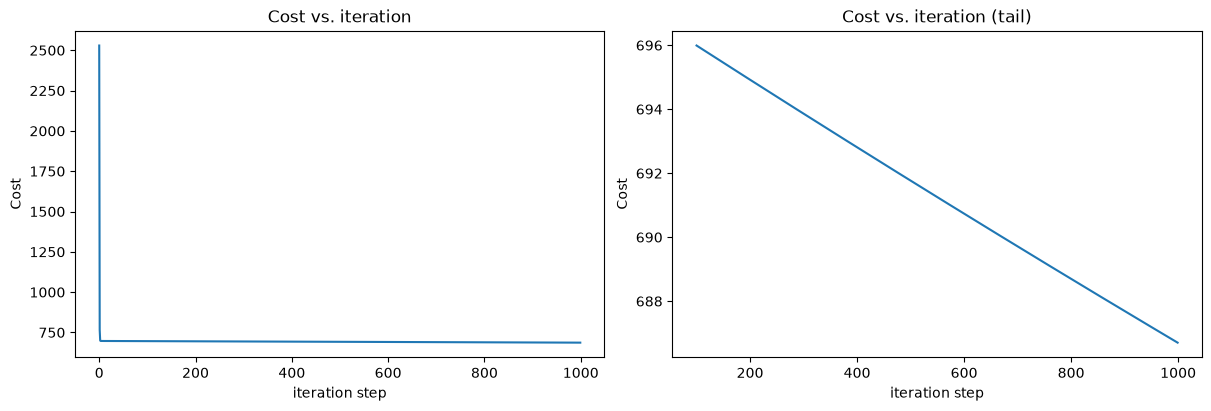

In [13]:
# plot cost versus iteration  
fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True, figsize=(12, 4))
ax1.plot(J_hist)
ax2.plot(100 + np.arange(len(J_hist[100:])), J_hist[100:])
ax1.set_title("Cost vs. iteration");  ax2.set_title("Cost vs. iteration (tail)")
ax1.set_ylabel('Cost')             ;  ax2.set_ylabel('Cost') 
ax1.set_xlabel('iteration step')   ;  ax2.set_xlabel('iteration step') 
plt.show()